This example showcases "X" cards (like "Y" and "Z") which specify general quadric surfaces that are axisymmetric w.r.t the specified axis. 

OpenMC does have general quadric surfaces but cannot automatically construct quadrics axisymmetric about an axis, given three points. The quadric equations must be solved; this is not too hard with Sympy, which is not one of the module requirements that naturally comes with the OpenMC API. 

In MCNP, a single TR can be made to apply to multiple surfaces because each TR has a number associated with it; in OpenMC, you'd have to use the .rotate and .translate method on all the desired regions.

In [1]:
import openmc
import numpy as np

# Surface definitions
s3 = openmc.XPlane(x0=-14)
s5 = openmc.XPlane(x0=14) 

Surface 4 is the general quadric surface which cell 2 uses in its definition.

In [2]:
import sympy as sp

p1 = (-14, 10, 0)
p2 = (0, 12, 0)
p3 = (14,10,0)
p4 = (0, 0, 12)

x1,y1,z1 = map(sp.sympify,p1)
x2,y2,z2 = map(sp.sympify,p2)
x3,y3,z3 = map(sp.sympify,p3)
x4,y4,z4 = map(sp.sympify,p4)
A,B,C,D,E,F,G,H,J,K = sp.symbols('A B C D E F G H J K')

eqs = []

# s3 is parallel to X
eqs += [
        sp.Eq(C,B),
        sp.Eq(D,0),
        sp.Eq(E,0),
        sp.Eq(F,0),
        sp.Eq(H,0),
        sp.Eq(J,0),
    ]

def quadric_eq(x,y,z):
    return A*x **2 + B*y**2 + C*z**2 + D*x*y + E *y*z + F*x*z +G*x + H*y + J*z + K

q1 = quadric_eq(x1,y1,z1)
q2 = quadric_eq(x2,y2,z2)
print(q2)
q3 = quadric_eq(x3,y3,z3)
q4 = quadric_eq(x4,y4,z4)
#print(q4)
eqs += [sp.Eq(equation, 0) for equation in [q1,q2,q3]]

unknowns = [A,B,C,D,E,F,G,H,J,K]

# Need to figure out how to get the system to solve for K? did this by inspection
eqs += [sp.Eq(K, -144)]

vals = sp.linsolve(eqs, unknowns)

# OpenMC does not appreciate being passed sympy objects, so need to convert to float.
quad_sol = next(iter(vals))
quad_sol_unp = [float(v.evalf()) for v in quad_sol]

for i in quad_sol_unp:
    print(i, type(i))
    
# unpack into surface definition
s4 = openmc.Quadric(*quad_sol_unp)

144*B + 12*H + K
0.22448979591836735 <class 'float'>
1.0 <class 'float'>
1.0 <class 'float'>
0.0 <class 'float'>
0.0 <class 'float'>
0.0 <class 'float'>
0.0 <class 'float'>
0.0 <class 'float'>
0.0 <class 'float'>
-144.0 <class 'float'>


We'll put this into a temporary cell so we can view the result, before we apply the TR card. That will occur after verifying that we have indeed produced the barrel shape.

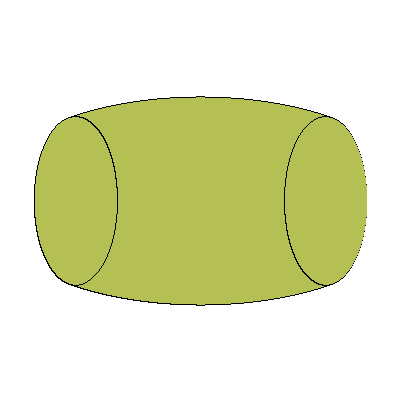

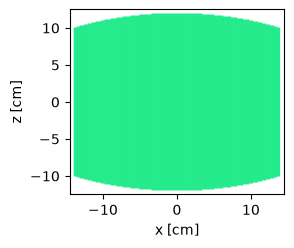

In [3]:
c2_region = +s3&-s4&-s5
c2_temp = openmc.Cell(fill=None,region=c2_region)
geometry = openmc.Geometry([c2_temp])

geometry.plot(width=(29,25),basis='xz')
geometry.export_to_xml()
#%cat geometry.xml

plots = openmc.Plots()
wf = openmc.WireframeRayTracePlot()
wf.camera_position=(0,-30,0)
wf.horizontal_field_of_view=(80)
wf.look_at=(0,0,0)
plots.append(wf)
openmc.plot_inline(plots)

The MCNP example specifies TR1 and TR2; the former uses m=1 and the latter m=-1. They are repeated here for convenience.

TR1 20 31 37 0.223954 0.358401 0.906308 

(Something seems off with the rotation)

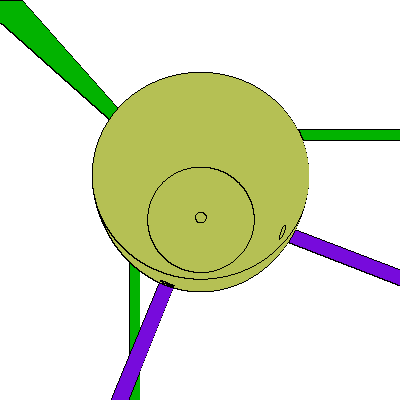

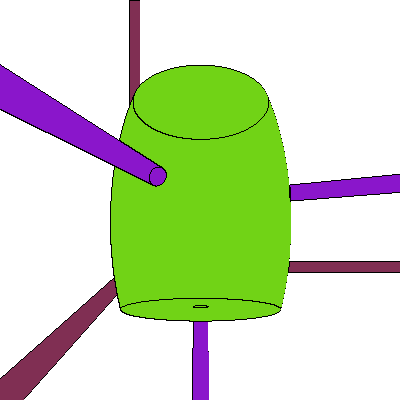

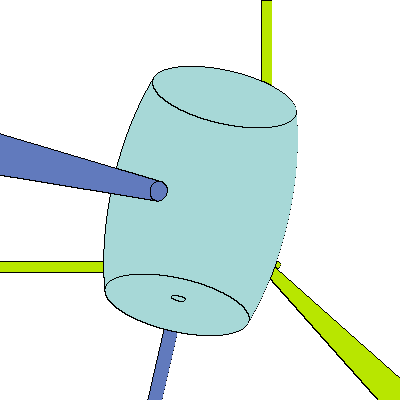

In [4]:
translate_1 = np.array([20,31,37])

rotate_1 = [[ 0.223954, 0.358401, 0.906308], [0, 0.929776, -0.368125]]
#rotate_1 = [[ 0.223954, 0.358401, 0.906308], [0,1, 0]]
rotate_1.append(np.cross(rotate_1[0],rotate_1[1]))
rotate_1 = np.array(rotate_1)
#print(rotate_1, np.linalg.det(rotate_1)) 
# need to check that this matrix doesn't skew/shear

c2_region_TR = c2_region.rotate(rotate_1)
c2_region_TR = c2_region_TR.translate(translate_1)
c2 = openmc.Cell(fill=None,region=c2_region_TR)
#c2.plot(width=(40,40),origin=translate_1,basis='xy')
#c2.plot(width=(40,40),origin=translate_1,basis='yz')
#c2.plot(width=(40,40),origin=translate_1,basis='xz')

ds1 = openmc.XCylinder(r=1)
dp1 = openmc.Plane(1,1,1,-1)
ds2 = openmc.YCylinder(r=1)
ds3 = openmc.ZCylinder(r=1)
base_diag = ((-ds1&+dp1)|(-ds2&+dp1)|(-ds3&+dp1))
diag_region = base_diag.rotate(rotate_1)
diag_region = diag_region.translate(translate_1)
diag_cell = openmc.Cell(fill=None,region=diag_region)
diag_region_2 = base_diag.translate((20-12,31-12,37-12))
diag_cell_2 = openmc.Cell(fill=None,region=diag_region_2)
geometry = openmc.Geometry([c2,diag_cell,diag_cell_2])
geometry.export_to_xml()
#%cat geometry.xml

plots = openmc.Plots()

# XY plot
wf = openmc.WireframeRayTracePlot()
wf.name = 'XY'
wf.up=np.array([1,0,0]) # this doesn't work. 
wf.camera_position= translate_1 + np.array([0.01, 0, 40])
wf.look_at=translate_1
wf.opaque_domains=[diag_cell,diag_cell_2]
#print(wf.up, wf.camera_position - wf.look_at)
plots.append(wf)

# YZ plot
wf = openmc.WireframeRayTracePlot()
wf.name = 'YZ'
wf.camera_position= translate_1 + np.array([40, 0.01, 0])
wf.look_at=translate_1
plots.append(wf)

# XZ plot
wf = openmc.WireframeRayTracePlot()
wf.name = 'XZ'
wf.camera_position= translate_1 + np.array([0.01, 40, 0])
wf.look_at=translate_1
plots.append(wf)

openmc.plot_inline(plots)

In [5]:
plots = openmc.Plots()
vox = openmc.VoxelPlot()
vox.filename = 'ex16_c2'
vox.pixels = (300, 300, 300)
vox.width = (40, 40, 40)
vox.origin = translate_1
plots.append(vox)
plots.export_to_xml()
res = openmc.plot_geometry(output=False);
print(res)
openmc.voxel_to_vtk(vox.filename+'.h5', vox.filename+'.vti')

None


'ex16_c2.vti'

Cell 6 is for the case of TR with m=-1, which just changed the order of the displacement vector; it now points from the new coordinate system to the main coordinate system. 
Simply inverting the signs provides the correct translation tuple for OpenMC.

TR2 -250 -100 -65 0.675849 0.669131 0.309017 J J 0.918650 J J -0.246152 -1

Cell 6 is composed of the union of a chopped cone, with a cylinder with rounded ends. 

<Axes: xlabel='x [cm]', ylabel='y [cm]'>

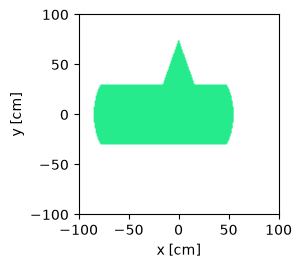

In [8]:
s13 = openmc.Sphere(x0=-15,r=70)
s14 = openmc.XCylinder(r=30)
s15 = openmc.YCone(y0=75,r2= 1.26419e-01)
s41 = openmc.YPlane()
s42 = openmc.YPlane(y0=75)

                   
c6_region = (-s14 & -s13 ) | (-s15 & +s41 & -s42)
c6_temp = openmc.Cell(fill=None,region=c6_region)
c6_temp.plot(width=(200,200))

translation_2 = np.array([250, 100, 65])
rotate_2 = np.array([[0.675849, 0.669131 ,0.309017 ],[J J 0.918650 J J -0.246152 -1